# Evaluación comparativa — Telco Customer Churn (P2)

**Propósito:** comparar el Dummy Classifier, la regresión logística y el árbol de decisión sobre **Test**, con las configuraciones ya cerradas en P03 y P04, y analizar en qué clientes se equivoca cada modelo.

**Qué se hace en este notebook:**

1. Se vuelven a ajustar los tres modelos **solo con Train**, usando las configuraciones guardadas en `resultados/configuracion_*.json`, y se comprueba que reproducen las métricas de Validation.
2. Se evalúan sobre **Test** con las cinco métricas del protocolo y sus matrices de confusión.
3. Se calculan intervalos de confianza del 95 % con bootstrap pareado, para saber qué diferencias entre modelos se pueden distinguir con 1409 clientes.
4. Se analizan los errores: por tipo de cliente, coincidencia entre modelos y perfil de los falsos negativos y de los falsos positivos.

**Ejecución:** seguir las celdas en orden, después de `P03_regresion_logistica.ipynb` y `P04_arbol_decision.ipynb` (este notebook lee las configuraciones que ellos guardan en `resultados/`). Funciona desde la raíz del repositorio, desde `notebooks/` o en Google Colab.

> **Importante:** este es el único notebook que usa Test. Ningún hiperparámetro, umbral ni variable se modificó después de ver estos resultados. Volver a ejecutarlo reproduce los mismos números; lo que no se hace es tomar decisiones a partir de ellos.

## 1. Importación de librerías y localización del proyecto

In [1]:
import sys
import subprocess
import time
from pathlib import Path

# Se busca la raíz del repositorio en el directorio actual, en el directorio padre
# y en las ubicaciones habituales (misma lógica que en P02).
PROJECT_NAME = "Machine-Learning-Project"
REPO_URL = "https://github.com/sofkp/Machine-Learning-Project.git"

candidatos = [
    Path.cwd(),
    Path.cwd().parent,
    Path.cwd() / PROJECT_NAME,
    Path.cwd().parent / PROJECT_NAME,
    Path("/content") / PROJECT_NAME,
]


def es_raiz(ruta):
    return (ruta / "preprocessing.py").is_file() and (ruta / "src" / "protocolo.py").is_file()


ROOT = next((ruta.resolve() for ruta in candidatos if es_raiz(ruta)), None)

# En Colab, si el repositorio todavía no está en el entorno, se clona.
if ROOT is None and "google.colab" in sys.modules:
    destino = Path("/content") / PROJECT_NAME
    if not destino.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(destino)], check=True)
    if es_raiz(destino):
        ROOT = destino.resolve()

if ROOT is None:
    raise FileNotFoundError(
        "No se encontró el repositorio (preprocessing.py y la carpeta src/). "
        "Clónalo y ejecuta este notebook desde su raíz o desde notebooks/."
    )

sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from sklearn.dummy import DummyClassifier

from src import analisis, graficos
from src.modelos import crear_arbol_decision, crear_regresion_logistica
from src.protocolo import (
    METRICAS,
    NOMBRE_ARBOL,
    NOMBRE_DUMMY,
    NOMBRE_LOGISTICA,
    RESULTS_DIR,
    calcular_metricas,
    cargar_particiones,
    evaluar_modelo,
    guardar_tabla,
    leer_json,
    matriz_confusion,
    predecir,
    tabla_metricas,
    versiones,
)

graficos.aplicar_estilo()
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_columns", 30)
pd.set_option("display.max_colwidth", 80)

print("Carpeta del proyecto:", ROOT.name)
print("Versiones:", versiones())

Carpeta del proyecto: Machine-Learning-Project
Versiones: {'python': '3.12.13', 'numpy': '2.4.6', 'pandas': '2.2.3', 'scikit-learn': '1.6.1'}


## 2. Datos y particiones

Se recuperan las tres particiones de `split_data()` (60/20/20, estratificadas, semilla 42). Test tiene el mismo tamaño que Validation y la misma proporción de abandono.

In [2]:
X_train, X_val, X_test, y_train, y_val, y_test = cargar_particiones()

for nombre, (X, y) in {"Train": (X_train, y_train), "Validation": (X_val, y_val), "Test": (X_test, y_test)}.items():
    print(f"{nombre:<11}{len(X):>5} clientes | abandonos: {int(y.sum()):>4} ({100 * y.mean():.2f} %)")

# Ningún cliente aparece en más de una partición.
assert not (set(X_train.index) & set(X_val.index)) and not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))

Train       4225 clientes | abandonos: 1121 (26.53 %)
Validation  1409 clientes | abandonos:  374 (26.54 %)
Test        1409 clientes | abandonos:  374 (26.54 %)


## 3. Modelos finales

Las configuraciones se leen de los archivos que guardaron P03 y P04. Siguiendo el protocolo de P02, los modelos se ajustan **solo con Train** (no se reentrena con Train + Validation).

Antes de tocar Test se comprueba que los modelos reajustados aquí obtienen en Validation las mismas métricas registradas durante la selección. Si no coincidieran, no serían los mismos modelos.

In [3]:
config_logistica = leer_json("configuracion_regresion_logistica.json")
config_arbol = leer_json("configuracion_arbol_decision.json")

print(f"{NOMBRE_LOGISTICA}: configuración {config_logistica['configuracion']} -> {config_logistica['hiperparametros']}")
print(f"{NOMBRE_ARBOL}:   configuración {config_arbol['configuracion']} -> {config_arbol['hiperparametros']}")

modelos = {
    NOMBRE_DUMMY: DummyClassifier(strategy="most_frequent"),
    NOMBRE_LOGISTICA: crear_regresion_logistica(**config_logistica["hiperparametros"]),
    NOMBRE_ARBOL: crear_arbol_decision(**config_arbol["hiperparametros"]),
}
for modelo in modelos.values():
    modelo.fit(X_train, y_train)  # preprocesador y clasificador se ajustan solo con Train

# Comprobación: las métricas de Validation deben coincidir con las guardadas en P02, P03 y P04.
metricas_validation = {nombre: evaluar_modelo(modelo, X_val, y_val) for nombre, modelo in modelos.items()}
baseline = pd.read_csv(RESULTS_DIR / "resultados_baseline_validacion.csv", encoding="utf-8-sig", index_col="Modelo")
registradas = {
    NOMBRE_DUMMY: baseline.loc[NOMBRE_DUMMY, METRICAS].to_dict(),
    NOMBRE_LOGISTICA: config_logistica["metricas_validation"],
    NOMBRE_ARBOL: config_arbol["metricas_validation"],
}
print("\nDiferencia máxima con las métricas de Validation registradas:")
for nombre in modelos:
    diferencia = max(abs(metricas_validation[nombre][m] - registradas[nombre][m]) for m in METRICAS)
    print(f" - {nombre}: {diferencia:.1e}")
    assert diferencia < 1e-4, (
        f"{nombre} no reproduce sus métricas de Validation. Vuelve a ejecutar P03 y P04 en este entorno."
    )

Regresión logística: configuración 14 -> {'penalizacion': 'l2', 'class_weight': 'balanced', 'C': 0.1}
Árbol de decisión:   configuración 41 -> {'class_weight': 'balanced', 'max_depth': None, 'min_samples_leaf': 20}



Diferencia máxima con las métricas de Validation registradas:
 - Dummy Classifier: 0.0e+00
 - Regresión logística: 0.0e+00
 - Árbol de decisión: 0.0e+00


## 4. Resultados en Test

Se usan las mismas cinco métricas, el mismo umbral de 0,5 y la misma clase positiva (`Churn=1`) que en Validation. La tabla muestra los dos conjuntos lado a lado: **Validation** es donde se eligieron las configuraciones, y **Test** es la estimación del desempeño en clientes que no participaron en ninguna decisión.

In [4]:
predicciones_test = {nombre: predecir(modelo, X_test) for nombre, modelo in modelos.items()}
metricas_test = {nombre: calcular_metricas(y_test, *predicciones_test[nombre]) for nombre in modelos}

comparacion = pd.concat(
    [tabla_metricas(metricas_validation, "Validation"), tabla_metricas(metricas_test, "Test")]
).reset_index().set_index(["Modelo", "Conjunto"]).loc[list(modelos)]

print("Métricas de los tres modelos en Validation y en Test:")
display(comparacion.round(3))

cambio = (pd.DataFrame(metricas_test) - pd.DataFrame(metricas_validation)).T[METRICAS]
cambio.index.name = "Modelo"
print("Cambio de Validation a Test (Test − Validation):")
display(cambio.round(3))

Métricas de los tres modelos en Validation y en Test:


Accuracy  Precision  Recall  F1-score  ROC-AUC
Modelo              Conjunto                                                  
Dummy Classifier    Validation     0.735      0.000   0.000     0.000    0.500
                    Test           0.735      0.000   0.000     0.000    0.500
Regresión logística Validation     0.748      0.517   0.791     0.625    0.836
                    Test           0.743      0.510   0.781     0.617    0.841
Árbol de decisión   Validation     0.757      0.531   0.743     0.619    0.819
                    Test           0.744      0.512   0.722     0.599    0.818

Cambio de Validation a Test (Test − Validation):


,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,
Dummy Classifier,0.000,0.000,0.000,0.000,0.000
Regresión logística,-0.005,-0.006,-0.011,-0.008,0.006
Árbol de decisión,-0.013,-0.018,-0.021,-0.020,-0.001


**Lectura.** En Test, la regresión logística obtiene F1 = 0.617 y el árbol de decisión F1 = 0.599, frente a F1 = 0 del Dummy. En ROC-AUC, 0.841 y 0.818 frente a 0.5.

Dos cosas que conviene mirar en esta tabla:

- **Validation frente a Test.** Los resultados de Test son un poco menores que los de Validation: el F1 baja 0.008 en la regresión logística y 0.020 en el árbol. Es lo esperable, porque cada configuración se eligió justamente por ser la mejor en Validation y ese número queda algo optimista. La caída es algo mayor en el árbol, lo que es coherente con el mayor sobreajuste que mostró en P04, aunque las dos caídas son pequeñas frente al margen de incertidumbre que se calcula en la sección 6. El ROC-AUC prácticamente no cambia (0.836 → 0.841 y 0.819 → 0.818).
- **El Accuracy engaña.** Los tres modelos tienen casi el mismo Accuracy (0.735, 0.743 y 0.744), aunque el Dummy no detecta ningún abandono. Con el 73.5 % de clientes en la clase "No", acertar mucho no significa detectar abandonos; por eso el criterio del proyecto es el F1 de `Churn=1`.

## 5. Matrices de confusión en Test

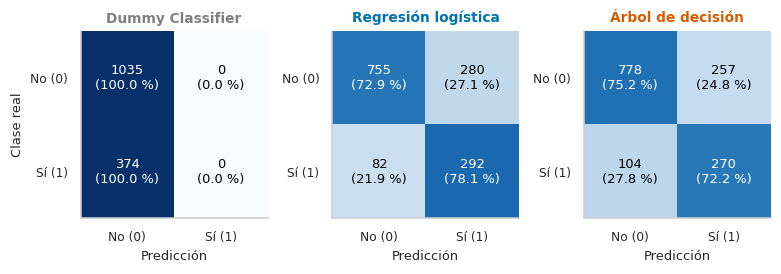

,"VN (se queda, sin alerta)",FP (falsa alarma),FN (abandono no detectado),VP (abandono detectado),Alertas emitidas,Alertas (% de clientes)
Modelo,,,,,,
Dummy Classifier,1035,0,374,0,0,0.0
Regresión logística,755,280,82,292,572,40.6
Árbol de decisión,778,257,104,270,527,37.4


In [5]:
matrices_test = {nombre: matriz_confusion(y_test, predicciones_test[nombre][0]) for nombre in modelos}

figura = graficos.figura_matrices(matrices_test)
graficos.guardar_figura(figura, "p05_matrices_confusion_test.png")
plt.show()

conteos = pd.DataFrame(
    {
        nombre: {
            "VN (se queda, sin alerta)": matriz.iloc[0, 0],
            "FP (falsa alarma)": matriz.iloc[0, 1],
            "FN (abandono no detectado)": matriz.iloc[1, 0],
            "VP (abandono detectado)": matriz.iloc[1, 1],
            "Alertas emitidas": matriz.iloc[:, 1].sum(),
        }
        for nombre, matriz in matrices_test.items()
    }
).T
conteos.index.name = "Modelo"
conteos["Alertas (% de clientes)"] = (100 * conteos["Alertas emitidas"] / len(y_test)).round(1)
display(conteos)

**Lectura.** De los 374 clientes de Test que abandonaron, la regresión logística detecta 292 (78.1 %) y el árbol 270 (72.2 %). A cambio, la regresión logística da 280 falsas alarmas entre los 1035 clientes que se quedaron (27.1 %) y el árbol 257 (24.8 %).

Visto desde las alertas: la regresión logística marca al 40.6 % de los clientes y el árbol al 37.4 %, y en ambos casos más o menos la mitad de las alertas corresponde a un abandono real (Precision de 0.510 y 0.512). Los dos modelos son igual de precisos; la diferencia es que la regresión logística alerta a más clientes y por eso encuentra 22 abandonos más, con 23 falsas alarmas más.

## 6. ¿Qué diferencias son distinguibles? Intervalos bootstrap

Test tiene 1409 clientes y 374 abandonos, así que cada métrica tiene un margen de incertidumbre. Para medirlo se usa un **bootstrap pareado**: se remuestrean los clientes de Test con reemplazo 2000 veces y, en cada remuestreo, se evalúan los tres modelos sobre **los mismos clientes**. El intervalo del 95 % va del percentil 2.5 al 97.5.

Al ser pareado, también da un intervalo para la **diferencia** entre dos modelos. Si ese intervalo incluye el cero, la diferencia observada puede deberse a qué clientes cayeron en Test.

In [6]:
intervalos, diferencias = analisis.bootstrap_pareado(
    y_test,
    predicciones_test,
    comparaciones=[(NOMBRE_LOGISTICA, NOMBRE_ARBOL), (NOMBRE_LOGISTICA, NOMBRE_DUMMY), (NOMBRE_ARBOL, NOMBRE_DUMMY)],
    n_remuestreos=2000,
)


def con_intervalo(fila, columna):
    return f"{fila[columna]:.3f} [{fila['IC inferior']:.3f}, {fila['IC superior']:.3f}]"


tabla_intervalos = (
    intervalos.assign(Texto=intervalos.apply(con_intervalo, axis=1, columna="Estimación"))
    .pivot(index="Modelo", columns="Métrica", values="Texto").loc[list(modelos), METRICAS]
)
print("Métricas en Test con intervalo de confianza del 95 %:")
display(tabla_intervalos)

tabla_diferencias = (
    diferencias.assign(Texto=diferencias.apply(con_intervalo, axis=1, columna="Diferencia"))
    .pivot(index="Comparación", columns="Métrica", values="Texto")
    .loc[list(dict.fromkeys(diferencias["Comparación"])), METRICAS]
)
print("Diferencias entre modelos en Test con intervalo de confianza del 95 %:")
display(tabla_diferencias)

excluyen = diferencias[diferencias["El IC excluye 0"]].groupby("Comparación", sort=False)["Métrica"].apply(list)
print("Métricas cuyo intervalo de la diferencia excluye el cero:")
for comparacion_modelos in dict.fromkeys(diferencias["Comparación"]):
    print(f" - {comparacion_modelos}: {excluyen.get(comparacion_modelos, []) or 'ninguna'}")

Métricas en Test con intervalo de confianza del 95 %:


Métrica,Accuracy,Precision,Recall,F1-score,ROC-AUC
Modelo,,,,,
Dummy Classifier,"0.735 [0.711, 0.759]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.000 [0.000, 0.000]","0.500 [0.500, 0.500]"
Regresión logística,"0.743 [0.720, 0.766]","0.510 [0.470, 0.551]","0.781 [0.736, 0.820]","0.617 [0.579, 0.654]","0.841 [0.818, 0.863]"
Árbol de decisión,"0.744 [0.720, 0.765]","0.512 [0.469, 0.554]","0.722 [0.675, 0.767]","0.599 [0.559, 0.635]","0.818 [0.793, 0.841]"


Diferencias entre modelos en Test con intervalo de confianza del 95 %:


Métrica,Accuracy,Precision,Recall,F1-score,ROC-AUC
Comparación,,,,,
Regresión logística − Árbol de decisión,"-0.001 [-0.021, 0.020]","-0.002 [-0.027, 0.025]","0.059 [0.016, 0.103]","0.018 [-0.009, 0.049]","0.023 [0.009, 0.040]"
Regresión logística − Dummy Classifier,"0.009 [-0.025, 0.041]","0.510 [0.470, 0.551]","0.781 [0.736, 0.820]","0.617 [0.579, 0.654]","0.341 [0.318, 0.363]"
Árbol de decisión − Dummy Classifier,"0.009 [-0.023, 0.040]","0.512 [0.469, 0.554]","0.722 [0.675, 0.767]","0.599 [0.559, 0.635]","0.318 [0.293, 0.341]"


Métricas cuyo intervalo de la diferencia excluye el cero:
 - Regresión logística − Árbol de decisión: ['Recall', 'ROC-AUC']
 - Regresión logística − Dummy Classifier: ['Precision', 'Recall', 'F1-score', 'ROC-AUC']
 - Árbol de decisión − Dummy Classifier: ['Precision', 'Recall', 'F1-score', 'ROC-AUC']


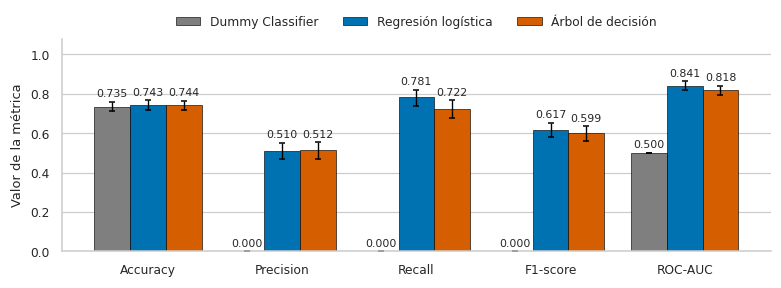

In [7]:
figura = graficos.figura_metricas(intervalos)
graficos.guardar_figura(figura, "p05_metricas_test.png")
plt.show()

**Lectura.** Hay dos comparaciones que revisar:

- **Frente al Dummy.** Los intervalos de las diferencias en Precision, Recall, F1 y ROC-AUC quedan muy lejos del cero: los dos modelos aportan información real. La excepción es el Accuracy: la diferencia es de +0.009 tanto para la regresión logística (intervalo [−0.025, 0.041]) como para el árbol ([−0.023, 0.040]). Con estos datos no se puede afirmar que acierten más que predecir siempre "No".
- **Regresión logística frente a árbol.** La regresión logística tiene mayor Recall (+0.059 [0.016, 0.103]) y mayor ROC-AUC (+0.023 [0.009, 0.040]), y en ambos casos el intervalo excluye el cero. En F1 la diferencia es de +0.018 [−0.009, 0.049]: apunta en la misma dirección, pero el intervalo incluye el cero, así que **no se puede afirmar que la regresión logística tenga mejor F1**. En Precision (−0.002) y Accuracy (−0.001) son prácticamente iguales.

En resumen: con la misma precisión, la regresión logística detecta más abandonos y ordena mejor a los clientes por riesgo. La ventaja en F1 no es concluyente con 1409 clientes.

Una advertencia: se calculan 15 intervalos sin corrección por comparaciones múltiples, y todos se basan en una sola partición de los datos. Sirven para dimensionar la incertidumbre, no como prueba definitiva.

## 7. Curvas ROC y Precision-Recall

Las métricas anteriores dependen del umbral de 0,5. Las curvas muestran qué pasaría con cualquier otro umbral: la curva ROC relaciona los abandonos detectados con las falsas alarmas, y la curva Precision-Recall muestra cuánta precisión se pierde al intentar detectar más abandonos. El punto marcado en cada curva es el umbral de 0,5 que usa el proyecto.

Estas curvas son **descriptivas**: el umbral no se ajusta con ellas, porque eso sería tomar una decisión mirando Test.

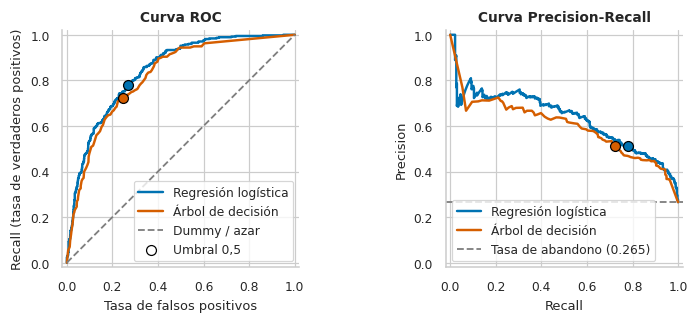

Regresión logística: 1407 probabilidades distintas entre los 1409 clientes de Test
Árbol de decisión: 101 probabilidades distintas entre los 1409 clientes de Test


In [8]:
figura = graficos.figura_roc_pr(y_test, predicciones_test)
graficos.guardar_figura(figura, "p05_curvas_roc_pr_test.png")
plt.show()

for nombre in (NOMBRE_LOGISTICA, NOMBRE_ARBOL):
    distintas = len(np.unique(predicciones_test[nombre][1]))
    print(f"{nombre}: {distintas} probabilidades distintas entre los {len(y_test)} clientes de Test")

**Lectura.** La curva ROC de la regresión logística queda por encima de la del árbol en casi todo el rango, lo que coincide con su mayor ROC-AUC (0.841 frente a 0.818). En la curva Precision-Recall los dos modelos superan con claridad la línea punteada (0.265), que es la precisión que se obtendría alertando al azar, y la curva de la regresión logística también queda por encima de la del árbol en casi todo el rango.

En el umbral de 0,5 (los puntos marcados) ambos modelos tienen casi la misma precisión, y la regresión logística queda más a la derecha: más Recall. La curva del árbol tiene tramos rectos porque todos los clientes que caen en una misma hoja reciben la misma probabilidad: en Test solo aparecen unos 100 valores distintos, mientras que la regresión logística asigna una probabilidad distinta a casi cada cliente.

## 8. Análisis de errores

Una métrica global no dice **a quién** le falla el modelo. En esta sección se revisan los errores de la regresión logística y del árbol de decisión en Test (el Dummy no se incluye: se equivoca exactamente en todos los clientes que abandonan).

### 8.1 Errores por tipo de cliente

Se usan los grupos que en el EDA de P1 mostraron las mayores diferencias de abandono (contrato, antigüedad e internet), más `SeniorCitizen`, `PaymentMethod` y `gender`. En cada grupo se miden dos cosas:

- **Recall:** de los clientes del grupo que abandonaron, qué proporción detectó el modelo.
- **TFP (tasa de falsos positivos):** de los clientes del grupo que se quedaron, qué proporción recibió una alerta.

In [9]:
supervisados = {nombre: predicciones_test[nombre] for nombre in (NOMBRE_LOGISTICA, NOMBRE_ARBOL)}
grupos = {
    "Contract": X_test["Contract"],
    "Antigüedad (meses)": analisis.grupo_antiguedad(X_test["tenure"]),
    "InternetService": X_test["InternetService"],
    "SeniorCitizen": X_test["SeniorCitizen"],
    "PaymentMethod": X_test["PaymentMethod"],
    "gender": X_test["gender"],
}
errores = analisis.errores_por_subgrupo(X_test, y_test, supervisados, grupos)
display(analisis.resumen_por_subgrupo(errores).round(3))

Clientes  Abandonos  \
Variable           Grupo                                            
Contract           Month-to-month                  773        329   
                   One year                        300         36   
                   Two year                        336          9   
Antigüedad (meses) 0–12                            449        215   
                   13–24                           206         60   
                   25–48                           304         64   
                   49–72                           450         35   
InternetService    Fiber optic                     613        252   
                   DSL                             484         97   
                   No                              312         25   
SeniorCitizen      0                              1187        276   
                   1                               222         98   
PaymentMethod      Bank transfer (automatic)       300         57   
                   Credit card (automatic)         309         51   
                   Electronic check                474        206   
                   Mailed check                    326         60   
gender             Female                          687        193   
                   Male                            722        181   

                                              Tasa de abandono  \
Variable           Grupo                                         
Contract           Month-to-month                        0.426   
                   One year                              0.120   
                   Two year                              0.027   
Antigüedad (meses) 0–12                                  0.479   
                   13–24                                 0.291   
                   25–48                                 0.211   
                   49–72                                 0.078   
InternetService    Fiber optic                           0.411   
                   DSL                                   0.200   
                   No                                    0.080   
SeniorCitizen      0                                     0.233   
                   1                                     0.441   
PaymentMethod      Bank transfer (automatic)             0.190   
                   Credit card (automatic)               0.165   
                   Electronic check                      0.435   
                   Mailed check                          0.184   
gender             Female                                0.281   
                   Male                                  0.251   

                                              Recall · Regresión logística  \
Variable           Grupo                                                     
Contract           Month-to-month                                    0.863   
                   One year                                          0.222   
                   Two year                                          0.000   
Antigüedad (meses) 0–12                                              0.842   
                   13–24                                             0.883   
                   25–48                                             0.688   
                   49–72                                             0.400   
InternetService    Fiber optic                                       0.905   
                   DSL                                               0.660   
                   No                                                0.000   
SeniorCitizen      0                                                 0.728   
                   1                                                 0.929   
PaymentMethod      Bank transfer (automatic)                         0.649   
                   Credit card (automatic)                           0.647   
                   Electronic check                                  0.903   
                  

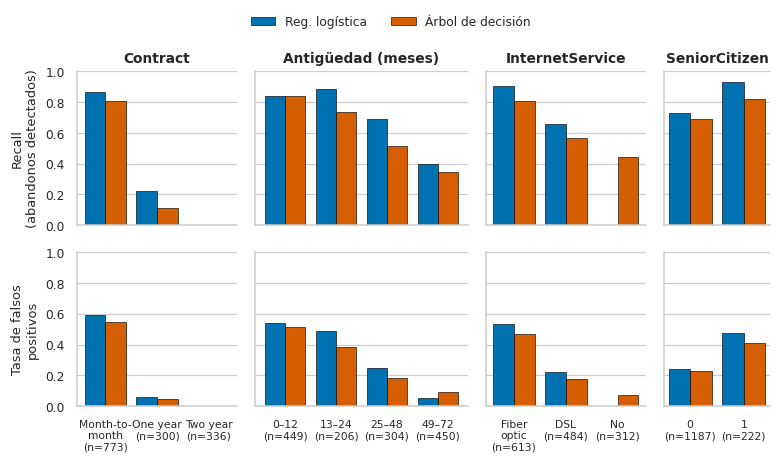

In [10]:
figura = graficos.figura_errores_subgrupo(
    errores, variables=["Contract", "Antigüedad (meses)", "InternetService", "SeniorCitizen"]
)
graficos.guardar_figura(figura, "p05_errores_por_subgrupo_test.png")
plt.show()

**Lectura.** Los errores no se reparten por igual entre los clientes:

- **Contrato.** En `Month-to-month` los dos modelos detectan la mayoría de los abandonos (Recall de 0.863 y 0.809), pero también alertan sobre más de la mitad de los clientes que se quedan (TFP de 0.595 y 0.550). Con contratos largos ocurre lo contrario: casi no hay falsas alarmas, pero se detectan 8 y 4 de los 36 abandonos con contrato de un año, y **ninguno** de los 9 abandonos con contrato de dos años.
- **Antigüedad.** El Recall es alto durante los dos primeros años (entre 0.733 y 0.883) y después cae: en los clientes de 49–72 meses es de 0.400 en la regresión logística y de 0.343 en el árbol.
- **Internet.** Entre los clientes sin internet, la regresión logística no detecta ninguno de los 25 abandonos; el árbol detecta 11, con algunas falsas alarmas más (TFP de 0.073 frente a 0.003). Es el único grupo en el que el árbol detecta claramente más abandonos.
- **`SeniorCitizen` y `PaymentMethod`.** Los grupos con más abandono (adultos mayores y pago con cheque electrónico) tienen más Recall y también más falsas alarmas: en la regresión logística, TFP de 0.476 y 0.578.
- **Género.** No hay diferencias apreciables (en la regresión logística, Recall de 0.782 y 0.779, y TFP de 0.271 y 0.270).

El patrón general es que los modelos aprendieron bien el perfil típico del abandono (contrato mensual, poca antigüedad, fibra óptica). Tratan como riesgo a buena parte de los clientes con ese perfil y a casi nadie fuera de él. Algunos grupos tienen muy pocos abandonos (9 con contrato de dos años, 25 sin internet), así que sus tasas son poco precisas.

### 8.2 ¿Los dos modelos se equivocan con los mismos clientes?

Si ambos modelos fallan en los mismos clientes, el problema está en la información disponible y no en el tipo de modelo.

In [11]:
coincidencia = analisis.coincidencia_de_errores(
    y_test, predicciones_test[NOMBRE_LOGISTICA][0], predicciones_test[NOMBRE_ARBOL][0],
    NOMBRE_LOGISTICA, NOMBRE_ARBOL,
)
display(coincidencia.round(3).set_index(["Clase real", "Situación"]))

iguales = (predicciones_test[NOMBRE_LOGISTICA][0] == predicciones_test[NOMBRE_ARBOL][0]).mean()
print(f"Los dos modelos dan la misma predicción en el {100 * iguales:.1f} % de los clientes de Test.")

Clientes  \
Clase real                         Situación                                             
Clientes que abandonaron (Churn=1) Ambos modelos: detecta                          249   
                                   Solo Regresión logística: detecta                43   
                                   Solo Árbol de decisión: detecta                  21   
                                   Ninguno: detecta                                 61   
Clientes que se quedaron (Churn=0) Ambos modelos: da falsa alarma                  193   
                                   Solo Regresión logística: da falsa alarma        87   
                                   Solo Árbol de decisión: da falsa alarma          64   
                                   Ninguno: da falsa alarma                        691   

                                                                              Proporción  
Clase real                         Situación                                              
Clientes que abandonaron (Churn=1) Ambos modelos: detecta                          0.666  
                                   Solo Regresión logística: detecta               0.115  
                                   Solo Árbol de decisión: detecta                 0.056  
                                   Ninguno: detecta                                0.163  
Clientes que se quedaron (Churn=0) Ambos modelos: da falsa alarma                  0.186  
                                   Solo Regresión logística: da falsa alarma       0.084  
                                   Solo Árbol de decisión: da falsa alarma         0.062  
                                   Ninguno: da falsa alarma                        0.668

Los dos modelos dan la misma predicción en el 84.7 % de los clientes de Test.


**Lectura.** Los dos modelos dan la misma predicción para el 84.7 % de los clientes. De los 374 abandonos, 249 (66.6 %) son detectados por ambos y 61 (16.3 %) por ninguno; la regresión logística detecta 43 que el árbol no detecta, y el árbol 21 que la regresión logística no.

Dicho de otra forma, 61 de los 82 falsos negativos de la regresión logística (74 %) también son falsos negativos del árbol, y 193 de sus 280 falsas alarmas (69 %) también lo son. Que dos modelos tan distintos fallen en los mismos clientes sugiere que el límite está en la **información disponible**, más que en el tipo de modelo.

### 8.3 Perfil de los falsos negativos y de los falsos positivos

Se describe a los clientes según el resultado de la predicción: abandonos detectados (VP), abandonos no detectados (FN), falsas alarmas (FP) y clientes que se quedan sin alerta (VN).

In [12]:
perfiles = {}
for nombre in (NOMBRE_LOGISTICA, NOMBRE_ARBOL):
    perfiles[nombre] = analisis.perfil_de_resultados(X_test, y_test, predicciones_test[nombre][0])
    print(nombre)
    display(perfiles[nombre].round(1).astype(object).T)

Regresión logística


Resultado,VP (abandono detectado),FN (abandono no detectado),FP (falsa alarma),"VN (se queda, sin alerta)"
Clientes,292,82,280,755
tenure (mediana),6.0,26.0,16.0,49.0
MonthlyCharges (mediana),79.2,57.1,79.1,54.6
Contract = Month-to-month (%),97.3,54.9,94.3,23.8
InternetService = Fiber optic (%),78.1,29.3,68.9,22.3
PaymentMethod = Electronic check (%),63.7,24.4,55.4,15.0
SeniorCitizen = 1 (%),31.2,8.5,21.1,8.6


Árbol de decisión


Resultado,VP (abandono detectado),FN (abandono no detectado),FP (falsa alarma),"VN (se queda, sin alerta)"
Clientes,270,104,257,778
tenure (mediana),4.0,28.0,15.0,47.0
MonthlyCharges (mediana),77.1,71.3,75.6,58.4
Contract = Month-to-month (%),98.5,60.6,94.9,25.7
InternetService = Fiber optic (%),75.6,46.2,65.8,24.7
PaymentMethod = Electronic check (%),63.0,34.6,47.9,18.6
SeniorCitizen = 1 (%),29.6,17.3,19.8,9.4


**Lectura.** En los dos modelos se repite lo mismo:

- **Los abandonos no detectados (FN) no se parecen al abandono típico.** En la regresión logística tienen una mediana de 26 meses de antigüedad (6 en los detectados), solo el 54.9 % tiene contrato mensual (97.3 % en los detectados) y solo el 29.3 % tiene fibra óptica (78.1 %). En el árbol, la mediana de antigüedad es de 28 meses frente a 4.
- **Las falsas alarmas (FP) sí se parecen a los abandonos detectados.** En la regresión logística, el 94.3 % tiene contrato mensual, el 68.9 % fibra óptica y su cargo mensual mediano es casi idéntico (79.1 frente a 79.2). La diferencia más visible es que llevan más tiempo como clientes (mediana de 16 meses frente a 6).

Las falsas alarmas, entonces, no son errores absurdos: son clientes con el mismo perfil de riesgo que los que se fueron, pero que no abandonaron en el periodo observado. Con las 19 variables del dataset, ninguno de los dos modelos logra separarlos.

### 8.4 Probabilidades estimadas

Hasta aquí se evaluó la decisión (alerta o no). También conviene mirar las probabilidades que hay detrás, porque en la práctica podrían usarse para ordenar a los clientes por riesgo.

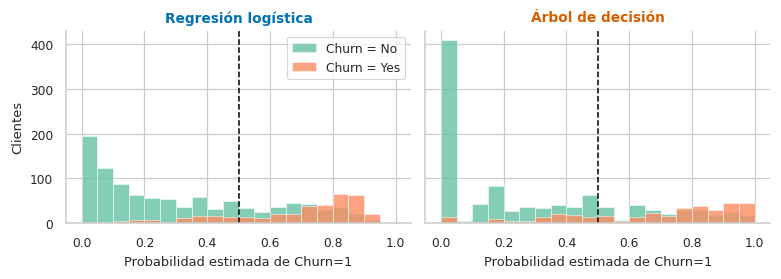

Modelo,Regresión logística,Árbol de decisión
Tasa real de abandono,0.265,0.265
Probabilidad media estimada,0.414,0.389
"Proporción de alertas (umbral 0,5)",0.406,0.374
Probabilidad media si Churn=1,0.677,0.673
Probabilidad media si Churn=0,0.319,0.287


Árbol de decisión: asigna probabilidad 0 a 424 clientes de Test; 14 de ellos abandonaron.


In [13]:
figura = graficos.figura_probabilidades(y_test, predicciones_test)
graficos.guardar_figura(figura, "p05_probabilidades_test.png")
plt.show()

display(analisis.resumen_de_probabilidades(y_test, supervisados).round(3).T)

en_cero = predicciones_test[NOMBRE_ARBOL][1] == 0
print(
    f"{NOMBRE_ARBOL}: asigna probabilidad 0 a {int(en_cero.sum())} clientes de Test; "
    f"{int(np.asarray(y_test)[en_cero].sum())} de ellos abandonaron."
)

**Lectura.** Los dos modelos sobrestiman la frecuencia del abandono: la probabilidad media estimada es de 0.414 en la regresión logística y de 0.389 en el árbol, cuando la tasa real en Test es de 0.265. Es una consecuencia directa de `class_weight="balanced"`: el modelo aprende como si las dos clases fueran igual de frecuentes.

Por eso las probabilidades sirven para **ordenar** a los clientes por riesgo (eso es lo que mide el ROC-AUC), pero no deben leerse como "este cliente tiene un 70 % de probabilidad de irse" sin calibrarlas antes.

En la figura también se nota la diferencia entre los modelos: la regresión logística reparte las probabilidades de forma continua, y el árbol las concentra en unos pocos valores. La barra de la izquierda son los 424 clientes que caen en hojas donde ningún cliente de Train abandonó: el árbol les asigna probabilidad 0, pero 14 de ellos (3.3 %) sí abandonaron. Que en un grupo no se hayan observado abandonos no significa que su riesgo real sea cero.

## 9. ¿En qué se apoya cada modelo?

Para comparar la interpretación de los dos modelos con una misma medida se usa la importancia por permutación calculada en P03 y P04 sobre **Validation** (caída del F1 al desordenar cada variable, 30 repeticiones). No se recalcula con Test.

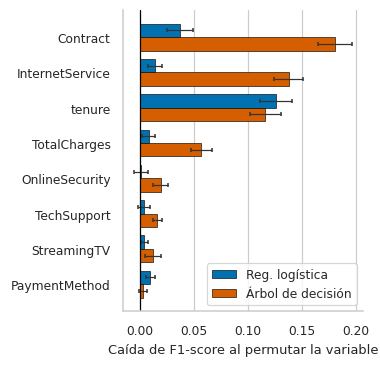

Caída de F1-score en Validation al permutar cada variable (las ocho mayores):


,Regresión logística,Árbol de decisión
Variable,,
Contract,0.038,0.180
InternetService,0.014,0.138
tenure,0.126,0.116
TotalCharges,0.008,0.057
OnlineSecurity,0.001,0.019
TechSupport,0.004,0.016
StreamingTV,0.004,0.012
PaymentMethod,0.010,0.003


In [14]:
permutacion_logistica = pd.read_csv(
    RESULTS_DIR / "importancia_permutacion_regresion_logistica_validacion.csv", encoding="utf-8-sig"
)
permutacion_arbol = pd.read_csv(
    RESULTS_DIR / "importancia_permutacion_arbol_decision_validacion.csv", encoding="utf-8-sig"
)

figura = graficos.figura_importancias(permutacion_logistica, permutacion_arbol, cantidad=8)
graficos.guardar_figura(figura, "p05_importancia_permutacion_validation.png")
plt.show()

columna = "Caída de F1-score (media)"
importancias = pd.concat(
    {
        NOMBRE_LOGISTICA: permutacion_logistica.set_index("Variable")[columna],
        NOMBRE_ARBOL: permutacion_arbol.set_index("Variable")[columna],
    },
    axis=1,
)
importancias = importancias.loc[importancias.max(axis=1).sort_values(ascending=False).index]
print("Caída de F1-score en Validation al permutar cada variable (las ocho mayores):")
display(importancias.head(8).round(3))

**Lectura.** Los dos modelos se apoyan sobre todo en las mismas tres variables (`tenure`, `Contract` e `InternetService`), que están entre las que el EDA de P1 había señalado, pero con distinto peso:

- La **regresión logística** depende sobre todo de `tenure` (el F1 cae 0.126 al permutarla) y mucho menos de `Contract` (0.038) e `InternetService` (0.014).
- El **árbol** reparte su dependencia entre `Contract` (0.180), `InternetService` (0.138) y `tenure` (0.116), y además usa `TotalCharges` (0.057).

Una explicación razonable (no se comprobó con un experimento aparte) es la forma en que cada modelo usa la información redundante. La regresión logística reparte el peso entre columnas que comparten información (por ejemplo, el tipo de internet también se refleja en el cargo mensual y en los servicios adicionales), así que desordenar una sola variable le quita relativamente poco. El árbol, en cambio, decide por ramas: si se desordena la variable de una de las primeras divisiones, el cliente cae en la rama equivocada y todo lo que sigue se evalúa mal.

## 10. Exportar resultados

In [15]:
archivos = {NOMBRE_DUMMY: "dummy", NOMBRE_LOGISTICA: "regresion_logistica", NOMBRE_ARBOL: "arbol_decision"}

tabla_predicciones = pd.DataFrame({"Churn real": np.asarray(y_test)}, index=X_test.index)
tabla_predicciones.index.name = "Fila en el CSV original"
for nombre, (y_pred, y_proba) in predicciones_test.items():
    tabla_predicciones[f"Predicción · {nombre}"] = y_pred
    tabla_predicciones[f"Probabilidad · {nombre}"] = y_proba

tabla_perfiles = pd.concat(perfiles, names=["Modelo"])

rutas = [
    guardar_tabla(comparacion, "comparacion_modelos_validacion_test.csv"),
    guardar_tabla(intervalos, "intervalos_bootstrap_test.csv", index=False),
    guardar_tabla(diferencias, "diferencias_bootstrap_test.csv", index=False),
    guardar_tabla(errores, "errores_por_subgrupo_test.csv", index=False),
    guardar_tabla(coincidencia, "coincidencia_errores_test.csv", index=False),
    guardar_tabla(tabla_perfiles, "perfil_errores_test.csv"),
    guardar_tabla(tabla_predicciones, "predicciones_test.csv"),
]
rutas += [
    guardar_tabla(matrices_test[nombre], f"matriz_confusion_{archivos[nombre]}_test.csv") for nombre in modelos
]
print("Archivos creados en resultados/:")
for ruta in rutas:
    print(" -", ruta.name)
print("Figuras en resultados/figuras/: p05_metricas_test.png, p05_matrices_confusion_test.png, "
      "p05_curvas_roc_pr_test.png, p05_errores_por_subgrupo_test.png, p05_probabilidades_test.png, "
      "p05_importancia_permutacion_validation.png")

Archivos creados en resultados/:
 - comparacion_modelos_validacion_test.csv
 - intervalos_bootstrap_test.csv
 - diferencias_bootstrap_test.csv
 - errores_por_subgrupo_test.csv
 - coincidencia_errores_test.csv
 - perfil_errores_test.csv
 - predicciones_test.csv
 - matriz_confusion_dummy_test.csv
 - matriz_confusion_regresion_logistica_test.csv
 - matriz_confusion_arbol_decision_test.csv
Figuras en resultados/figuras/: p05_metricas_test.png, p05_matrices_confusion_test.png, p05_curvas_roc_pr_test.png, p05_errores_por_subgrupo_test.png, p05_probabilidades_test.png, p05_importancia_permutacion_validation.png


## 11. Conclusiones de la evaluación comparativa

- **Los dos modelos superan claramente al baseline.** En Test, F1 de 0.617 (regresión logística) y 0.599 (árbol) frente a 0 del Dummy, y ROC-AUC de 0.841 y 0.818 frente a 0.5. El Accuracy no lo refleja (0.743 y 0.744 frente a 0.735).
- **Regresión logística frente a árbol.** Con la misma precisión (0.51), la regresión logística detecta más abandonos (Recall +0.059, intervalo del 95 % [0.016, 0.103]) y ordena mejor a los clientes (ROC-AUC +0.023 [0.009, 0.040]). La diferencia de F1 (+0.018 [−0.009, 0.049]) no es concluyente.
- **Generalización.** De Validation a Test el F1 baja 0.008 en la regresión logística y 0.020 en el árbol: los resultados de Validation eran ligeramente optimistas, sobre todo en el árbol.
- **Errores.** Los dos modelos fallan casi en los mismos clientes. No detectan a quienes abandonan con contratos largos o mucha antigüedad, y dan falsas alarmas a clientes con contrato mensual, fibra óptica y poca antigüedad que no se van.
- **Probabilidades.** Sirven para ordenar clientes por riesgo, pero no están calibradas: sobrestiman la tasa de abandono.

Si hubiera que quedarse con un solo modelo, sería la regresión logística: detecta más abandonos y ordena mejor a los clientes sin perder precisión, baja menos al pasar a Test y es más simple (un coeficiente por columna frente a un árbol de 132 hojas). El árbol aporta reglas fáciles de explicar y detecta a parte de los clientes sin internet que abandonan, que la regresión logística no detecta. La interpretación, las limitaciones y las conclusiones del proyecto se desarrollan en `docs/P06_discusion_limitaciones_conclusiones.md`.